# 06 — QTAF-Net Ablation Study (3 Variants + Fine-Tuning)

**PathVQA | Kaggle GPU | Training entirely from scratch**

This notebook independently trains **three architecture ablations**, each followed by fine-tuning of its own best checkpoint:

1. **No attention:** replace question-guided spatial attention with global mean pooling.
2. **No type-aware fusion:** replace the two type-gated fusion pathways with one shared fusion pathway; retain the auxiliary type-prediction head to isolate the fusion change.
3. **Single answer head:** replace the separate yes/no and open answer heads with one **1,002-class** classifier (2 yes/no + 1,000 open answers). Retain the original attention, type-aware fusion and auxiliary type classifier; the answer classifier is not routed by oracle type.

All variants use the same cleaned PathVQA splits, question vocabulary, open-answer vocabulary, image preprocessing, random seed, optimizer, early stopping and fine-tuning procedure as the original QTAF-Net notebook. **No pretrained model or pretrained weights are loaded.** The existing late-fusion checkpoint is used **only to recover the fixed vocabulary dictionaries**, never model parameters.

**Fairness note:** these are single-seed comparisons and should not be interpreted as statistically significant without repeated runs. For the single-head variant, `overall_accuracy` is direct unified-head accuracy (no oracle type routing); the other variants use oracle routing, as in the original notebook. This difference must be disclosed in your report.

**Reference:** full QTAF-Net original 53.20% and fine-tuned **54.10%** oracle validation accuracy; fine-tuned predicted-routing 53.97%, type accuracy 99.78%.

## 1. Environment and reproducibility

**Execution guide (Kaggle):** Enable a GPU accelerator and Internet access for the initial `datasets` installation/download. Run the notebook from top to bottom. The vocabulary-loading section expects the original late-fusion checkpoint (`late_fusion_latest.pth`) to be available through a Kaggle input dataset or the working directory. Attach that checkpoint before running. Required Python packages include `datasets`, PyTorch, torchvision, NumPy, pandas, Pillow, Matplotlib and scikit-learn (where imported). Model checkpoints and backup ZIPs are written to `/kaggle/working`. The three `run_variant` calls train separate experiments and can take substantial GPU time.

In [1]:
# Install the Hugging Face dataset package and initialize libraries, seeds, and device.
!pip -q install datasets

import os, re, glob, hashlib, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Load PathVQA and remove training images overlapping validation

In [2]:
# Load the three PathVQA splits and remove train/validation image overlaps only from training.
dataset = load_dataset("flaviagiammarino/path-vqa")
for split in ("train", "validation", "test"):
    print(split, len(dataset[split]))

def image_hash(image):
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    return h.hexdigest()

val_hashes = {image_hash(s["image"]) for s in tqdm(dataset["validation"], desc="Hash validation")}
keep_indices = [
    i for i, s in enumerate(tqdm(dataset["train"], desc="Check training overlap"))
    if image_hash(s["image"]) not in val_hashes
]
clean_train = dataset["train"].select(keep_indices)
clean_val = dataset["validation"]
clean_test = dataset["test"]  # held out
print("Clean train:", len(clean_train), "Validation:", len(clean_val))
assert len(clean_train) == 19648, "Unexpected cleaning count; inspect dataset version."

README.md:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

data/train-00000-of-00007-f2d0e9ef9f022d(…): reconstructing file:   0%|          |  0.00B / 42.8MB            

data/train-00000-of-00007-f2d0e9ef9f022d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-47d8e0220bf6c9(…): reconstructing file:   0%|          |  0.00B / 81.0MB            

data/train-00001-of-00007-47d8e0220bf6c9(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-7fb5037c4c5da7(…): reconstructing file:   0%|          |  0.00B /  104MB            

... (25 outputs left out)

Hash validation:   0%|          | 0/6259 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Check training overlap:   0%|          | 0/19654 [00:00<?, ?it/s]

Clean train: 19648 Validation: 6259


## 3. Load original vocabulary mappings only (no pretrained weights)

In [3]:
# Read the existing late-fusion checkpoint for vocabulary/answer mappings, not pretrained model weights.
candidates = sorted(
    glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
    + glob.glob("/kaggle/working/late_fusion_latest.pth")
)
for i, path in enumerate(candidates):
    print(i, path)
if len(candidates) != 1:
    raise RuntimeError("Attach exactly one original late_fusion_latest.pth checkpoint.")
# Load only checkpoints you created and trust.
saved = torch.load(candidates[0], map_location="cpu", weights_only=False)
word2idx = saved["word2idx"]
open_answer2idx = saved["open_answer2idx"]
del saved
assert len(open_answer2idx) == 1000
assert word2idx["<PAD>"] == 0 and word2idx["<UNK>"] == 1
print("Question vocabulary:", len(word2idx))
print("Open answer vocabulary:", len(open_answer2idx))

0 /kaggle/input/datasets/dollarpaisa/cnn-bilstam/late_fusion_latest.pth
Question vocabulary: 3972
Open answer vocabulary: 1000


## 4. Encode questions and answers

In [4]:
# Convert questions to fixed-length token IDs and map answers to the appropriate output classes.
MAX_QUESTION_LENGTH = 32

def encode_question(text):
    tokens = re.findall(r"\w+|[^\w\s]", str(text).lower().strip())
    ids = [word2idx.get(token, word2idx["<UNK>"]) for token in tokens[:MAX_QUESTION_LENGTH]]
    return ids + [word2idx["<PAD>"]] * (MAX_QUESTION_LENGTH - len(ids))

def encode_answer(answer):
    answer = str(answer).lower().strip()
    if answer == "no": return 0, 0
    if answer == "yes": return 0, 1
    return 1, open_answer2idx.get(answer, -1)

open_total = open_covered = 0
for answer in clean_val["answer"]:
    kind, label = encode_answer(answer)
    if kind == 1:
        open_total += 1
        open_covered += int(label >= 0)
print(f"Open-answer coverage: {open_covered}/{open_total} = {open_covered/open_total:.2%}")

Open-answer coverage: 2086/3134 = 66.56%


## 5. Image preprocessing (224×224, aspect-ratio preserving white padding)

In [5]:
# Resize and pad RGB pathology images consistently without distorting their aspect ratios.
IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB")
    image = ImageOps.contain(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.BILINEAR)
    background = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (255, 255, 255))
    background.paste(image, ((IMAGE_SIZE - image.width)//2, (IMAGE_SIZE - image.height)//2))
    array = np.asarray(background, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1)

print("Image tensor:", preprocess_image(clean_train[0]["image"]).shape)

Image tensor: torch.Size([3, 224, 224])


## 6. DataLoaders (batch size 32)

In [6]:
# Create PyTorch datasets and loaders for images, question tokens, answer types, and labels.
class PathVQAQTAFDataset(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        example = self.data[idx]
        answer_type, answer_label = encode_answer(example["answer"])
        return {
            "image": preprocess_image(example["image"]),
            "question": torch.tensor(encode_question(example["question"]), dtype=torch.long),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long),
        }

train_dataset = PathVQAQTAFDataset(clean_train)
val_dataset = PathVQAQTAFDataset(clean_val)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2,
                        pin_memory=torch.cuda.is_available())
batch = next(iter(train_loader))
for k, v in batch.items(): print(k, tuple(v.shape))
print("Train batches:", len(train_loader), "Validation batches:", len(val_loader))

image (32, 3, 224, 224)
question (32, 32)
answer_type (32,)
answer_label (32,)
Train batches: 614 Validation batches: 196


## 7. Shared scratch encoders and ablation architectures

The shared image encoder outputs 784 spatial vectors (28×28×256); the question encoder is a trainable embedding and BiLSTM. No model weights are imported. The single-head model's class IDs are: `0=no`, `1=yes`, `2+k=open answer k`. Unseen open answers are excluded from training loss and always counted incorrect in validation.

**Controlled comparison:** All three variants reuse the same data preparation and training framework. Only the component under study is changed: (A) attention is replaced by mean pooling, (B) question-type-aware fusion is removed, or (C) separate answer heads are replaced by a single classifier. This isolates the intended architecture choices, although the models are still subject to single-run training variability.

In [7]:
# Define shared scratch encoders and the three controlled QTAF-Net ablation architectures.
class SpatialImageEncoder(nn.Module):
    def __init__(self, dim=256):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),nn.BatchNorm2d(128),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1),nn.BatchNorm2d(256),nn.ReLU())
        self.project = nn.Conv2d(256,dim,1)
    def forward(self,x):
        return self.project(self.cnn(x)).flatten(2).transpose(1,2)

class QuestionEncoder(nn.Module):
    def __init__(self,vocab_size):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,128,padding_idx=0)
        self.lstm=nn.LSTM(128,128,batch_first=True,bidirectional=True)
    def forward(self,ids):
        lengths=(ids!=0).sum(1).clamp(min=1)
        packed=nn.utils.rnn.pack_padded_sequence(self.embedding(ids),lengths.cpu(),batch_first=True,enforce_sorted=False)
        _,(h,_)=self.lstm(packed)
        return torch.cat([h[-2],h[-1]],dim=1)

class AblatedQTAFNet(nn.Module):
    def __init__(self,vocab_size,num_open_answers=1000,variant='no_attention'):
        super().__init__()
        assert variant in ('no_attention','no_type_fusion','single_head')
        self.variant=variant
        self.image_encoder=SpatialImageEncoder()
        self.question_encoder=QuestionEncoder(vocab_size)
        if variant!='no_attention':
            self.att_visual=nn.Linear(256,256)
            self.att_question=nn.Linear(256,256)
            self.att_score=nn.Linear(256,1)
        self.type_head=nn.Sequential(nn.Linear(256,128),nn.ReLU(),nn.Dropout(0.2),nn.Linear(128,2))
        if variant=='no_type_fusion':
            self.shared_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))
        else:
            self.closed_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))
            self.open_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))
        if variant=='single_head':
            self.answer_head=nn.Linear(256,2+num_open_answers)
        else:
            self.yes_no_head=nn.Linear(256,2)
            self.open_head=nn.Linear(256,num_open_answers)

    def forward(self,images,questions):
        spatial=self.image_encoder(images)
        question=self.question_encoder(questions)
        if self.variant=='no_attention':
            visual=spatial.mean(1)
        else:
            energy=torch.tanh(self.att_visual(spatial)+self.att_question(question).unsqueeze(1))
            attention=torch.softmax(self.att_score(energy).squeeze(-1),dim=1)
            visual=(spatial*attention.unsqueeze(-1)).sum(1)
        type_logits=self.type_head(question)
        joint=torch.cat([visual,question],dim=1)
        if self.variant=='no_type_fusion':
            fused=self.shared_fusion(joint)
        else:
            type_probs=torch.softmax(type_logits,dim=1)
            closed_feature=self.closed_fusion(joint)
            open_feature=self.open_fusion(joint)
            fused=type_probs[:,0:1]*closed_feature+type_probs[:,1:2]*open_feature
        if self.variant=='single_head':
            return self.answer_head(fused),type_logits
        return self.yes_no_head(fused),self.open_head(fused),type_logits

VARIANTS=('no_attention','no_type_fusion','single_head')
for name in VARIANTS:
    demo=AblatedQTAFNet(len(word2idx),len(open_answer2idx),name).to(device)
    with torch.no_grad():
        sample=next(iter(val_loader))
        outputs=demo(sample['image'][:2].to(device),sample['question'][:2].to(device))
    print(name,'shapes:',[tuple(x.shape) for x in outputs],
          'trainable parameters:',sum(p.numel() for p in demo.parameters() if p.requires_grad))
    del demo
if torch.cuda.is_available():torch.cuda.empty_cache()

no_attention shapes: [(2, 2), (2, 1000), (2, 2)] trainable parameters: 1781100
no_type_fusion shapes: [(2, 2), (2, 1000), (2, 2)] trainable parameters: 1781613
single_head shapes: [(2, 1002), (2, 2)] trainable parameters: 1912941


## 8. Training loss and validation

For dual-head variants, training uses the ground-truth type to select the supervised answer head; `overall_accuracy` is oracle-routed and `predicted_overall_accuracy` uses the model's predicted type. For the single-head variant, all answer labels map to one 1,002-class output and **both overall metrics are the same direct prediction**. `type_accuracy` still measures the auxiliary type classifier. Type loss weight is **0.3** for every variant. Validation denominators include all examples, including open answers outside the 1,000-class vocabulary.

In [11]:
# Compute the variant-specific supervised loss and validation accuracy using the appropriate answer head.
TYPE_LOSS_WEIGHT=0.3

def compute_loss(outputs,types,labels,variant):
    if variant=='single_head':
        answer_logits,type_logits=outputs
        valid=(labels>=0)
        targets=labels.clone()
        targets[types==1]+=2
        answer_loss=F.cross_entropy(answer_logits[valid],targets[valid]) if valid.any() else answer_logits.sum()*0
    else:
        yn,op,type_logits=outputs
        closed=types==0
        open_valid=(types==1)&(labels>=0)
        losses=[]
        if closed.any():losses.append(F.cross_entropy(yn[closed],labels[closed]))
        if open_valid.any():losses.append(F.cross_entropy(op[open_valid],labels[open_valid]))
        answer_loss=sum(losses)/len(losses) if losses else (yn.sum()+op.sum())*0
    return answer_loss+TYPE_LOSS_WEIGHT*F.cross_entropy(type_logits,types)

def train_one_epoch(model,loader,optimizer,device):
    model.train();total=0.;count=0
    for batch in tqdm(loader,desc='Training',leave=False):
        images=batch['image'].to(device,non_blocking=True)
        questions=batch['question'].to(device,non_blocking=True)
        types=batch['answer_type'].to(device)
        labels=batch['answer_label'].to(device)
        optimizer.zero_grad()
        outputs=model(images,questions)
        loss=compute_loss(outputs,types,labels,model.variant)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(),1.0)
        optimizer.step()
        total+=loss.item()*len(images);count+=len(images)
    return total/count

@torch.no_grad()
def validate(model,loader,device):
    model.eval()
    d=dict(total=0,closed=0,opened=0,oracle_closed=0,oracle_open=0,
           predicted_closed=0,predicted_open=0,type_correct=0)
    for batch in tqdm(loader,desc='Validation',leave=False):
        images=batch['image'].to(device,non_blocking=True)
        questions=batch['question'].to(device,non_blocking=True)
        types=batch['answer_type'].to(device)
        labels=batch['answer_label'].to(device)
        outputs=model(images,questions)
        if model.variant=='single_head':
            logits,type_logits=outputs
            prediction=logits.argmax(1)
            closed_hit=(types==0)&(prediction==labels)
            open_hit=(types==1)&(labels>=0)&(prediction==labels+2)
            # Single head predicts without oracle routing; no distinct oracle metric.
            predicted_closed_hit=closed_hit
            predicted_open_hit=open_hit
        else:
            yn,op,type_logits=outputs
            pred_type=type_logits.argmax(1)
            closed_hit=(types==0)&(yn.argmax(1)==labels)
            open_hit=(types==1)&(labels>=0)&(op.argmax(1)==labels)
            predicted_closed_hit=closed_hit&(pred_type==0)
            predicted_open_hit=open_hit&(pred_type==1)
        d['total']+=len(types)
        d['closed']+=(types==0).sum().item()
        d['opened']+=(types==1).sum().item()
        d['oracle_closed']+=closed_hit.sum().item()
        d['oracle_open']+=open_hit.sum().item()
        d['predicted_closed']+=predicted_closed_hit.sum().item()
        d['predicted_open']+=predicted_open_hit.sum().item()
        d['type_correct']+=(type_logits.argmax(1)==types).sum().item()
    return {
        'overall_accuracy':(d['oracle_closed']+d['oracle_open'])/d['total'],
        'closed_accuracy':d['oracle_closed']/max(1,d['closed']),
        'open_accuracy':d['oracle_open']/max(1,d['opened']),
        'predicted_overall_accuracy':(d['predicted_closed']+d['predicted_open'])/d['total'],
        'predicted_closed_accuracy':d['predicted_closed']/max(1,d['closed']),
        'predicted_open_accuracy':d['predicted_open']/max(1,d['opened']),
        'type_accuracy':d['type_correct']/d['total']
    }
print('Loss and validation functions ready.')

Loss and validation functions ready.


## 9. Train and fine-tune a single variant

Each variant gets **fresh randomly initialized weights**, Adam `lr=0.001`, weight decay `1e-5`, max 30 epochs, patience 5, gradient clipping 1.0. Fine-tuning reloads that variant's **best original checkpoint**, uses a **fresh Adam** `lr=0.0001`, max 10 epochs, patience 3. Checkpoints and CSV histories are named by variant. Selection uses `overall_accuracy` (oracle-routed for dual-head variants; direct accuracy for single-head).

In [13]:
# Train each variant from fresh weights, select its best checkpoint, then fine-tune at a lower learning rate.
WORKDIR='/kaggle/working'
os.makedirs(WORKDIR,exist_ok=True)

def run_variant(variant):
    assert variant in VARIANTS
    # Fresh initialization for each independent experiment.
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
    model=AblatedQTAFNet(len(word2idx),len(open_answer2idx),variant).to(device)
    prefix=os.path.join(WORKDIR,'qtaf_ablation_'+variant)
    best_path=prefix+'_best.pth'
    latest_path=prefix+'_latest.pth'
    history_path=prefix+'_history.csv'
    ft_best_path=prefix+'_finetuned_best.pth'
    ft_latest_path=prefix+'_finetune_latest.pth'
    ft_history_path=prefix+'_finetune_history.csv'

    def phase(phase_name,optimizer,max_epochs,patience,save_best,save_latest,save_history):
        best=-1.;best_epoch=0;stale=0;history=[]
        for epoch in range(1,max_epochs+1):
            loss=train_one_epoch(model,train_loader,optimizer,device)
            metrics=validate(model,val_loader,device)
            history.append({'epoch':epoch,'train_loss':loss,**metrics})
            print(f'{variant} | {phase_name} epoch {epoch:02d} | Loss {loss:.4f} | '
                  f'Overall {metrics["overall_accuracy"]:.2%} | '
                  f'Predicted {metrics["predicted_overall_accuracy"]:.2%} | '
                  f'Yes/No {metrics["closed_accuracy"]:.2%} | '
                  f'Open {metrics["open_accuracy"]:.2%} | Type {metrics["type_accuracy"]:.2%}')
            if metrics['overall_accuracy']>best:
                best=metrics['overall_accuracy'];best_epoch=epoch;stale=0
                torch.save(model.state_dict(),save_best)
                print('  Saved new best:',save_best)
            else:stale+=1
            torch.save({'epoch':epoch,'model_state_dict':model.state_dict(),
                        'optimizer_state_dict':optimizer.state_dict(),'history':history,
                        'best_accuracy':best,'best_epoch':best_epoch,'variant':variant,
                        'phase':phase_name,'word2idx':word2idx,
                        'open_answer2idx':open_answer2idx,
                        'type_loss_weight':TYPE_LOSS_WEIGHT},save_latest)
            pd.DataFrame(history).to_csv(save_history,index=False)
            if stale>=patience:
                print('  Early stopping');break
        model.load_state_dict(torch.load(save_best,map_location=device,weights_only=True))
        result=validate(model,val_loader,device)
        print(f'BEST {variant} {phase_name} | epoch {best_epoch} | overall {result["overall_accuracy"]:.2%}')
        return result,best_epoch

    optimizer=torch.optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-5)
    original,original_epoch=phase('original',optimizer,30,5,best_path,latest_path,history_path)
    # phase() reloads the best original weights, not the last epoch.
    optimizer_ft=torch.optim.Adam(model.parameters(),lr=0.0001,weight_decay=1e-5)
    finetuned,finetuned_epoch=phase('finetuned',optimizer_ft,10,3,ft_best_path,ft_latest_path,ft_history_path)
    result={'variant':variant,'original_best_epoch':original_epoch,
            'finetuned_best_epoch':finetuned_epoch,
            'original_overall_accuracy':original['overall_accuracy'],
            **{'finetuned_'+k:v for k,v in finetuned.items()},
            'original_checkpoint':best_path,'finetuned_checkpoint':ft_best_path}
    del model,optimizer,optimizer_ft
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return result

## 10. Ablation A — Without question-guided attention

Uses spatial **mean pooling** instead of learned question-guided attention; retains type-aware fusion and both answer heads. Train from scratch, then fine-tune.

In [14]:
# Run the no-attention experiment with spatial mean pooling.
result_no_attention=run_variant('no_attention')

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


no_attention | original epoch 01 | Loss 2.6074 | Overall 46.17% | Predicted 46.14% | Yes/No 82.40% | Open 10.05% | Type 99.78%
  Saved new best: /kaggle/working/qtaf_ablation_no_attention_best.pth


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (180 outputs left out)

no_attention | finetuned epoch 06 | Loss 0.8255 | Overall 54.58% | Predicted 54.47% | Yes/No 86.37% | Open 22.88% | Type 99.76%
  Early stopping


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


BEST no_attention finetuned | epoch 3 | overall 54.91%


## 11. Ablation B — Without question-type-aware fusion

Uses one shared fusion MLP instead of the predicted-type-weighted two-pathway fusion. Keeps attention, auxiliary question-type classifier and both answer heads. Train from scratch, then fine-tune.

In [15]:
# Run the no-type-fusion experiment with a shared fusion pathway.
result_no_type_fusion=run_variant('no_type_fusion')

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7db0da7e67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7db0da7e67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/p

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


no_type_fusion | original epoch 01 | Loss 2.6204 | Overall 44.05% | Predicted 43.92% | Yes/No 79.46% | Open 8.74% | Type 99.78%
  Saved new best: /kaggle/working/qtaf_ablation_no_type_fusion_best.pth


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (173 outputs left out)

no_type_fusion | finetuned epoch 07 | Loss 0.8130 | Overall 54.37% | Predicted 54.26% | Yes/No 86.46% | Open 22.37% | Type 99.78%
  Early stopping


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7db0da7e67a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7db0da7e67a0>
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
if w.is_alive():AssertionError
:   File "/usr/lib/python3.13/multiprocessing/pro

BEST no_type_fusion finetuned | epoch 4 | overall 54.71%


## 12. Ablation C — Single shared answer head

Uses one **1,002-way** answer head in place of the two answer heads, with a single cross-entropy loss over known answers. Keeps question-guided attention, predicted-type fusion, and the auxiliary type classifier. Because the head is unified, its answer accuracy does not depend on oracle routing. Train from scratch, then fine-tune.

In [16]:
# Run the single-head experiment with a unified answer classifier.
result_single_head=run_variant('single_head')

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


single_head | original epoch 01 | Loss 2.4429 | Overall 45.63% | Predicted 45.63% | Yes/No 82.59% | Open 8.77% | Type 99.78%
  Saved new best: /kaggle/working/qtaf_ablation_single_head_best.pth


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (192 outputs left out)

single_head | finetuned epoch 10 | Loss 0.6961 | Overall 54.58% | Predicted 54.58% | Yes/No 86.11% | Open 23.13% | Type 99.78%
  Saved new best: /kaggle/working/qtaf_ablation_single_head_finetuned_best.pth


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7db0da7e67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7db0da7e67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/p

BEST single_head finetuned | epoch 10 | overall 54.58%


## 13. Comparison table

**Interpret carefully:** full QTAF-Net and the first two ablations use oracle type routing for their headline accuracy; the single-head variant makes a direct 1,002-way prediction. This is a meaningful architectural comparison but the routing protocol differs. All rows use the same validation split. **Do not use the test split during model selection.**

**Results interpretation:** This table reports validation results, not the final held-out test set. Compare the same evaluation setting across models; the dual-head models use ground-truth answer-type routing during validation, while the single-head variant has no head-routing decision. The full-model reference is a comparison value, not a model retrained by this notebook.

In [17]:
# Combine ablation validation results with the full QTAF-Net reference for comparison.
results=[result_no_attention,result_no_type_fusion,result_single_head]
rows=[{'model':'Full QTAF-Net (reference)','original_overall_%':53.20,'finetuned_overall_%':54.10,
       'finetuned_yes_no_%':85.98,'finetuned_open_%':22.30,'finetuned_type_%':99.78,
       'delta_vs_full_pp':0.0,'routing':'Oracle'},]
for r in results:
    rows.append({'model':r['variant'],'original_overall_%':100*r['original_overall_accuracy'],
                 'finetuned_overall_%':100*r['finetuned_overall_accuracy'],
                 'finetuned_yes_no_%':100*r['finetuned_closed_accuracy'],
                 'finetuned_open_%':100*r['finetuned_open_accuracy'],
                 'finetuned_type_%':100*r['finetuned_type_accuracy'],
                 'delta_vs_full_pp':100*(r['finetuned_overall_accuracy']-0.5410),
                 'routing':'Direct single head' if r['variant']=='single_head' else 'Oracle'})
comparison=pd.DataFrame(rows)
display(comparison.round(2))
comparison.to_csv(os.path.join(WORKDIR,'qtaf_ablation_comparison.csv'),index=False)
print('Saved comparison CSV.')

,model,original_overall_%,finetuned_overall_%,finetuned_yes_no_%,finetuned_open_%,finetuned_type_%,delta_vs_full_pp,routing
0,Full QTAF-Net (reference),53.20,54.10,85.98,22.30,99.78,0.00,Oracle
1,no_attention,53.44,54.91,86.46,23.45,99.76,0.81,Oracle
2,no_type_fusion,54.13,54.71,86.72,22.78,99.78,0.61,Oracle
3,single_head,53.60,54.58,86.11,23.13,99.78,0.48,Direct single head


Saved comparison CSV.


## 14. Visualize accuracy and training curves

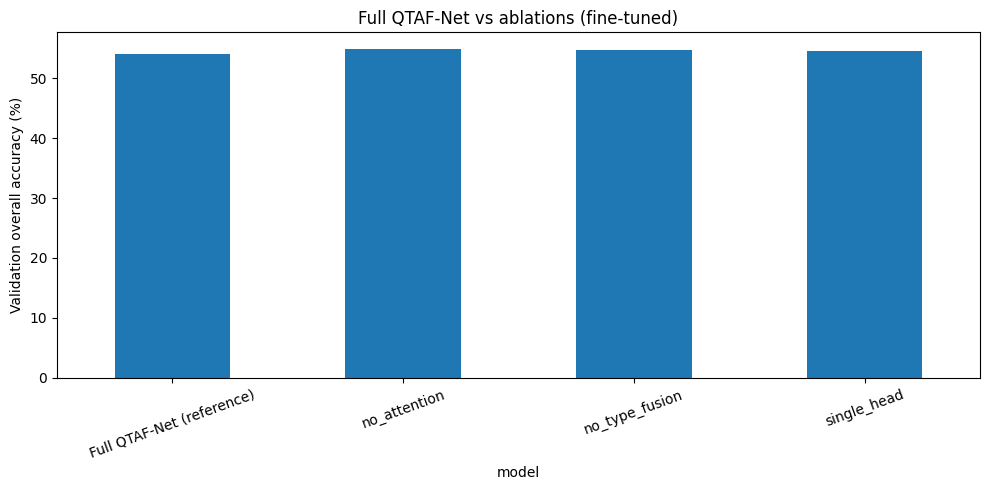

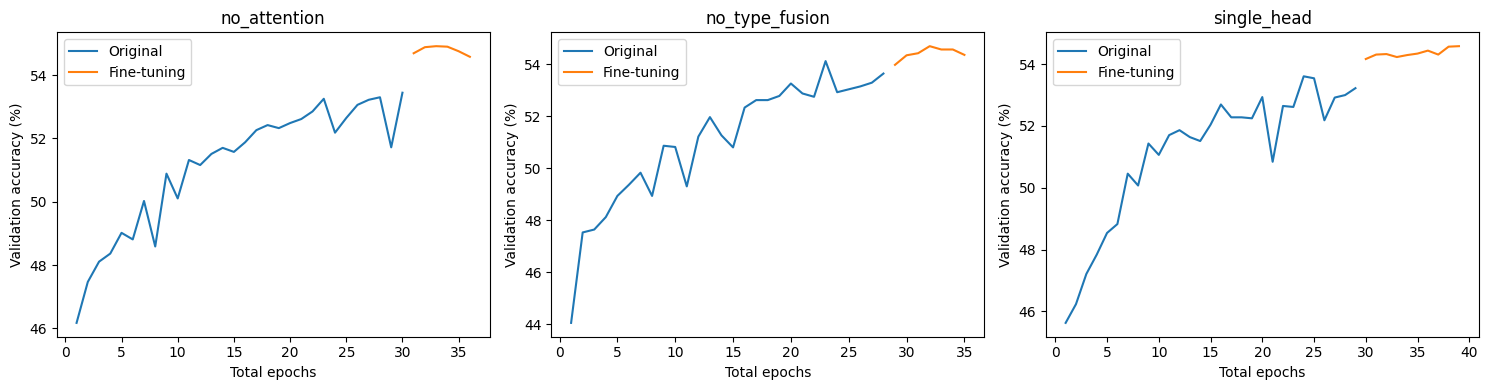

In [18]:
# Plot the fine-tuned validation accuracy and recorded training curves.
ax=comparison.plot.bar(x='model',y='finetuned_overall_%',legend=False,figsize=(10,5),rot=20)
ax.set_ylabel('Validation overall accuracy (%)')
ax.set_title('Full QTAF-Net vs ablations (fine-tuned)')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,name in zip(axes,VARIANTS):
    prefix=os.path.join(WORKDIR,'qtaf_ablation_'+name)
    original=pd.read_csv(prefix+'_history.csv')
    ft=pd.read_csv(prefix+'_finetune_history.csv')
    ax.plot(original['epoch'],original['overall_accuracy']*100,label='Original')
    ax.plot(original['epoch'].max()+ft['epoch'],ft['overall_accuracy']*100,label='Fine-tuning')
    ax.set_title(name);ax.set_xlabel('Total epochs');ax.set_ylabel('Validation accuracy (%)');ax.legend()
plt.tight_layout();plt.show()

## 15. Backup all experiment files

Download the ZIP and keep the separate original/fine-tuned `.pth` checkpoints for each variant. **Original full QTAF-Net checkpoints are never overwritten.**

**Optional export steps:** The following backup/download cells are convenience utilities. They assume the expected checkpoint files exist under `/kaggle/working`; if a ZIP path is different, inspect the saved files before using the optional download helper. These cells do not change the trained models.

In [30]:
# Bundle saved checkpoints and experiment artifacts into a Kaggle output ZIP.
import zipfile
archive=os.path.join(WORKDIR,'qtaf_ablation_backup.zip')
files=[]
for name in VARIANTS:
    files+=glob.glob(os.path.join(WORKDIR,'qtaf_ablation_'+name+'_*'))
files+=glob.glob(os.path.join(WORKDIR,'qtaf_ablation_comparison.csv'))
files=[p for p in files if os.path.isfile(p) and not p.endswith('.zip')]
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(set(files)):z.write(p,arcname=os.path.basename(p))
print('Backup:',archive,'Files:',len(set(files)))
for p in sorted(set(files)):print(' -',os.path.basename(p))

Backup: /kaggle/working/qtaf_ablation_backup.zip Files: 19
 - qtaf_ablation_comparison.csv
 - qtaf_ablation_no_attention_best.pth
 - qtaf_ablation_no_attention_finetune_history.csv
 - qtaf_ablation_no_attention_finetune_latest.pth
 - qtaf_ablation_no_attention_finetuned_best.pth
 - qtaf_ablation_no_attention_history.csv
 - qtaf_ablation_no_attention_latest.pth
 - qtaf_ablation_no_type_fusion_best.pth
 - qtaf_ablation_no_type_fusion_finetune_history.csv
 - qtaf_ablation_no_type_fusion_finetune_latest.pth
 - qtaf_ablation_no_type_fusion_finetuned_best.pth
 - qtaf_ablation_no_type_fusion_history.csv
 - qtaf_ablation_no_type_fusion_latest.pth
 - qtaf_ablation_single_head_best.pth
 - qtaf_ablation_single_head_finetune_history.csv
 - qtaf_ablation_single_head_finetune_latest.pth
 - qtaf_ablation_single_head_finetuned_best.pth
 - qtaf_ablation_single_head_history.csv
 - qtaf_ablation_single_head_latest.pth


In [31]:
# Create separate backups for each ablation variant if their artifacts are available.

import os
import glob
import zipfile

WORKDIR = "/kaggle/working"

variants = [
    "no_attention",
    "no_type_fusion",
    "single_head"
]

for variant in variants:
    prefix = f"qtaf_ablation_{variant}_"
    files = [
        p for p in glob.glob(os.path.join(WORKDIR, prefix + "*"))
        if os.path.isfile(p) and not p.endswith(".zip")
    ]

    zip_path = os.path.join(WORKDIR, f"{variant}_backup.zip")

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for file in files:
            z.write(file, arcname=os.path.basename(file))

    print(f"\nCreated: {zip_path}")
    print(f"Files included: {len(files)}")
    for file in files:
        print(" -", os.path.basename(file))



Created: /kaggle/working/no_attention_backup.zip
Files included: 6
 - qtaf_ablation_no_attention_finetune_latest.pth
 - qtaf_ablation_no_attention_finetuned_best.pth
 - qtaf_ablation_no_attention_latest.pth
 - qtaf_ablation_no_attention_history.csv
 - qtaf_ablation_no_attention_finetune_history.csv
 - qtaf_ablation_no_attention_best.pth

Created: /kaggle/working/no_type_fusion_backup.zip
Files included: 6
 - qtaf_ablation_no_type_fusion_finetuned_best.pth
 - qtaf_ablation_no_type_fusion_history.csv
 - qtaf_ablation_no_type_fusion_finetune_history.csv
 - qtaf_ablation_no_type_fusion_latest.pth
 - qtaf_ablation_no_type_fusion_best.pth
 - qtaf_ablation_no_type_fusion_finetune_latest.pth

Created: /kaggle/working/single_head_backup.zip
Files included: 6
 - qtaf_ablation_single_head_finetune_history.csv
 - qtaf_ablation_single_head_finetune_latest.pth
 - qtaf_ablation_single_head_latest.pth
 - qtaf_ablation_single_head_finetuned_best.pth
 - qtaf_ablation_single_head_history.csv
 - qtaf_abl

In [32]:
# Provide an optional browser-download helper for a chosen Kaggle ZIP archive.
from IPython.display import display, Javascript
import os

# Paste your ZIP file path here
zip_path = "/kaggle/working/no_type_fusion_backup.zip"

if not os.path.isfile(zip_path):
    print("File not found:", zip_path)
else:
    size = os.path.getsize(zip_path) / (1024 ** 2)
    print(f"File found: {size:.2f} MB")

    # Trigger browser download
    from urllib.parse import quote

    url = "/files/" + quote(
        os.path.relpath(zip_path, "/kaggle/working"),
        safe="/"
    )

    display(Javascript(f"""
        const link = document.createElement('a');
        link.href = {url!r};
        link.download = {os.path.basename(zip_path)!r};
        document.body.appendChild(link);
        link.click();
        link.remove();
    """))

File found: 51.23 MB


<IPython.core.display.Javascript object>

In [29]:
# Display an optional download link for the no-attention backup archive.
from IPython.display import FileLink, display
import os

file_path = "/kaggle/working/no_attention_backup.zip"

if os.path.exists(file_path):
    display(FileLink(file_path))
    print("File size:", round(os.path.getsize(file_path)/1024**2, 2), "MB")
else:
    print("File not found")

/kaggle/working/no_attention_backup.zip

File size: 50.9 MB


## 16. Reporting notes and next steps

- Use the best checkpoint of each variant, not the last epoch.
- All reported results here are **validation**, not test-set results.
- Report whether each removal increased or decreased accuracy; do not assume a component is beneficial.
- Keep original vs fine-tuned results separate, and report differences in **percentage points**.
- **Single-head caveat:** its direct 1,002-class accuracy is not an oracle-routed metric. State this explicitly.
- For stronger claims, repeat training with additional random seeds and report mean and standard deviation.
- Once ablations are complete, use the saved checkpoints in a shared final evaluation notebook for precision, recall, F1, BLEU and exact match. Do not calculate test results until the final evaluation stage.